In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('mental_health_burnout_tech_2026.csv')

In [3]:
df.head()

,employee_id,age,gender,country,job_role,seniority_level,years_experience,years_at_company,company_size,industry,...,autonomy_score,stress_score,burnout_score,phq9_score,phq9_category,gad7_score,gad7_category,burnout_level,seeks_mental_health_support,job_change_intention
0,1,33,Male,India,Software Engineer,Lead,11,6.4,Small (51-200),Healthcare Tech,...,6.1,10.0,10.0,19,Moderately Severe (15-19),12,Moderate (10-14),Severe,1,1
1,2,24,Non-binary,USA,Full Stack Developer,Manager,0,5.7,Startup (1-50),Fintech,...,5.4,9.3,7.0,8,Mild (5-9),6,Mild (5-9),High,1,1
2,3,36,Prefer not to say,USA,Software Engineer,Lead,14,5.6,Mid (201-1000),Fintech,...,4.1,8.9,8.5,8,Mild (5-9),9,Mild (5-9),Severe,0,1
3,4,38,Non-binary,USA,Software Engineer,Lead,14,1.2,Mid (201-1000),SaaS / Cloud,...,7.3,10.0,10.0,14,Moderate (10-14),11,Moderate (10-14),Severe,0,1
4,5,22,Non-binary,France,ML Engineer,Junior,0,3.0,Small (51-200),AI / ML Startup,...,4.4,7.7,5.4,8,Mild (5-9),0,Minimal (0-4),Moderate,1,0


In [4]:
df.shape

(100000, 36)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 36 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   employee_id                  100000 non-null  int64  
 1   age                          100000 non-null  int64  
 2   gender                       100000 non-null  object 
 3   country                      100000 non-null  object 
 4   job_role                     100000 non-null  object 
 5   seniority_level              100000 non-null  object 
 6   years_experience             100000 non-null  int64  
 7   years_at_company             100000 non-null  float64
 8   company_size                 100000 non-null  object 
 9   industry                     100000 non-null  object 
 10  work_mode                    100000 non-null  object 
 11  salary_usd                   100000 non-null  int64  
 12  work_hours_per_week          100000 non-null  int64  
 13  

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
employee_id,100000.0,50000.500000,28867.657797,1.0,25000.75,50000.5,75000.25,100000.0
age,100000.0,31.305670,6.427924,22.0,26.00,31.0,36.00,55.0
years_experience,100000.0,9.343690,6.401543,0.0,4.00,9.0,14.00,25.0
years_at_company,100000.0,2.492581,2.450426,0.1,0.70,1.7,3.50,15.0
salary_usd,100000.0,83285.490230,39392.584827,40000.0,46018.25,76630.5,109113.00,267961.0
work_hours_per_week,100000.0,47.104080,5.246902,35.0,44.00,47.0,51.00,72.0
meetings_per_day,100000.0,4.162244,1.937849,0.0,2.80,4.0,5.40,12.0
team_size,100000.0,18.009650,12.607473,2.0,8.00,16.0,25.00,59.0
sleep_hours_per_night,100000.0,6.102392,0.998808,3.0,5.40,6.1,6.80,10.0
exercise_days_per_week,100000.0,2.968730,1.772762,0.0,2.00,3.0,4.00,7.0


# EDA (Exploratory Data Analysis)

In [7]:
df['burnout_level'].unique()

array(['Severe', 'High', 'Moderate', 'Low'], dtype=object)

In [8]:
df['burnout_score'].unique()

array([10. ,  7. ,  8.5,  5.4,  7.4,  3.8,  3.9,  2.2,  4. ,  6. ,  4.7,
        5. ,  3.4,  6.7,  1.4,  5.3,  6.3,  6.4,  8.2,  0.3,  6.8,  4.9,
        6.5,  4.2,  6.9,  5.6,  4.3,  4.5,  3.1,  8.4,  3.3,  5.8,  0.7,
        6.2,  8.1,  4.8,  4.4,  8.3,  2.6,  1.9,  0. ,  2.8,  7.6,  3.7,
        5.7,  8.8,  8.9,  5.9,  9.5,  2.3,  9.1,  2.9,  7.9,  3. ,  5.1,
        5.5,  1.7,  6.6,  0.2,  9.2,  3.2,  3.5,  2. ,  2.5,  5.2,  2.4,
        7.2,  1.8,  7.7,  7.3,  2.7,  4.6,  1.6,  9.3,  0.9,  7.1,  8. ,
        7.8,  6.1,  2.1,  1.5,  1.1,  3.6,  9.6,  9.9,  8.6,  8.7,  9. ,
        0.5,  9.8,  4.1,  0.6,  7.5,  9.4,  0.1,  9.7,  1.2,  1.3,  0.8,
        1. ,  0.4])

In [9]:
df.select_dtypes(include='number').columns

Index(['employee_id', 'age', 'years_experience', 'years_at_company',
       'salary_usd', 'work_hours_per_week', 'meetings_per_day', 'team_size',
       'sleep_hours_per_night', 'exercise_days_per_week',
       'vacation_days_taken', 'therapy_access', 'uses_therapy',
       'ai_tools_daily', 'manager_support_score', 'work_life_balance_score',
       'job_satisfaction_score', 'social_support_score',
       'deadline_pressure_score', 'autonomy_score', 'stress_score',
       'burnout_score', 'phq9_score', 'gad7_score',
       'seeks_mental_health_support', 'job_change_intention'],
      dtype='object')

In [10]:
df.select_dtypes(include='object').columns

Index(['gender', 'country', 'job_role', 'seniority_level', 'company_size',
       'industry', 'work_mode', 'phq9_category', 'gad7_category',
       'burnout_level'],
      dtype='object')

<Axes: >

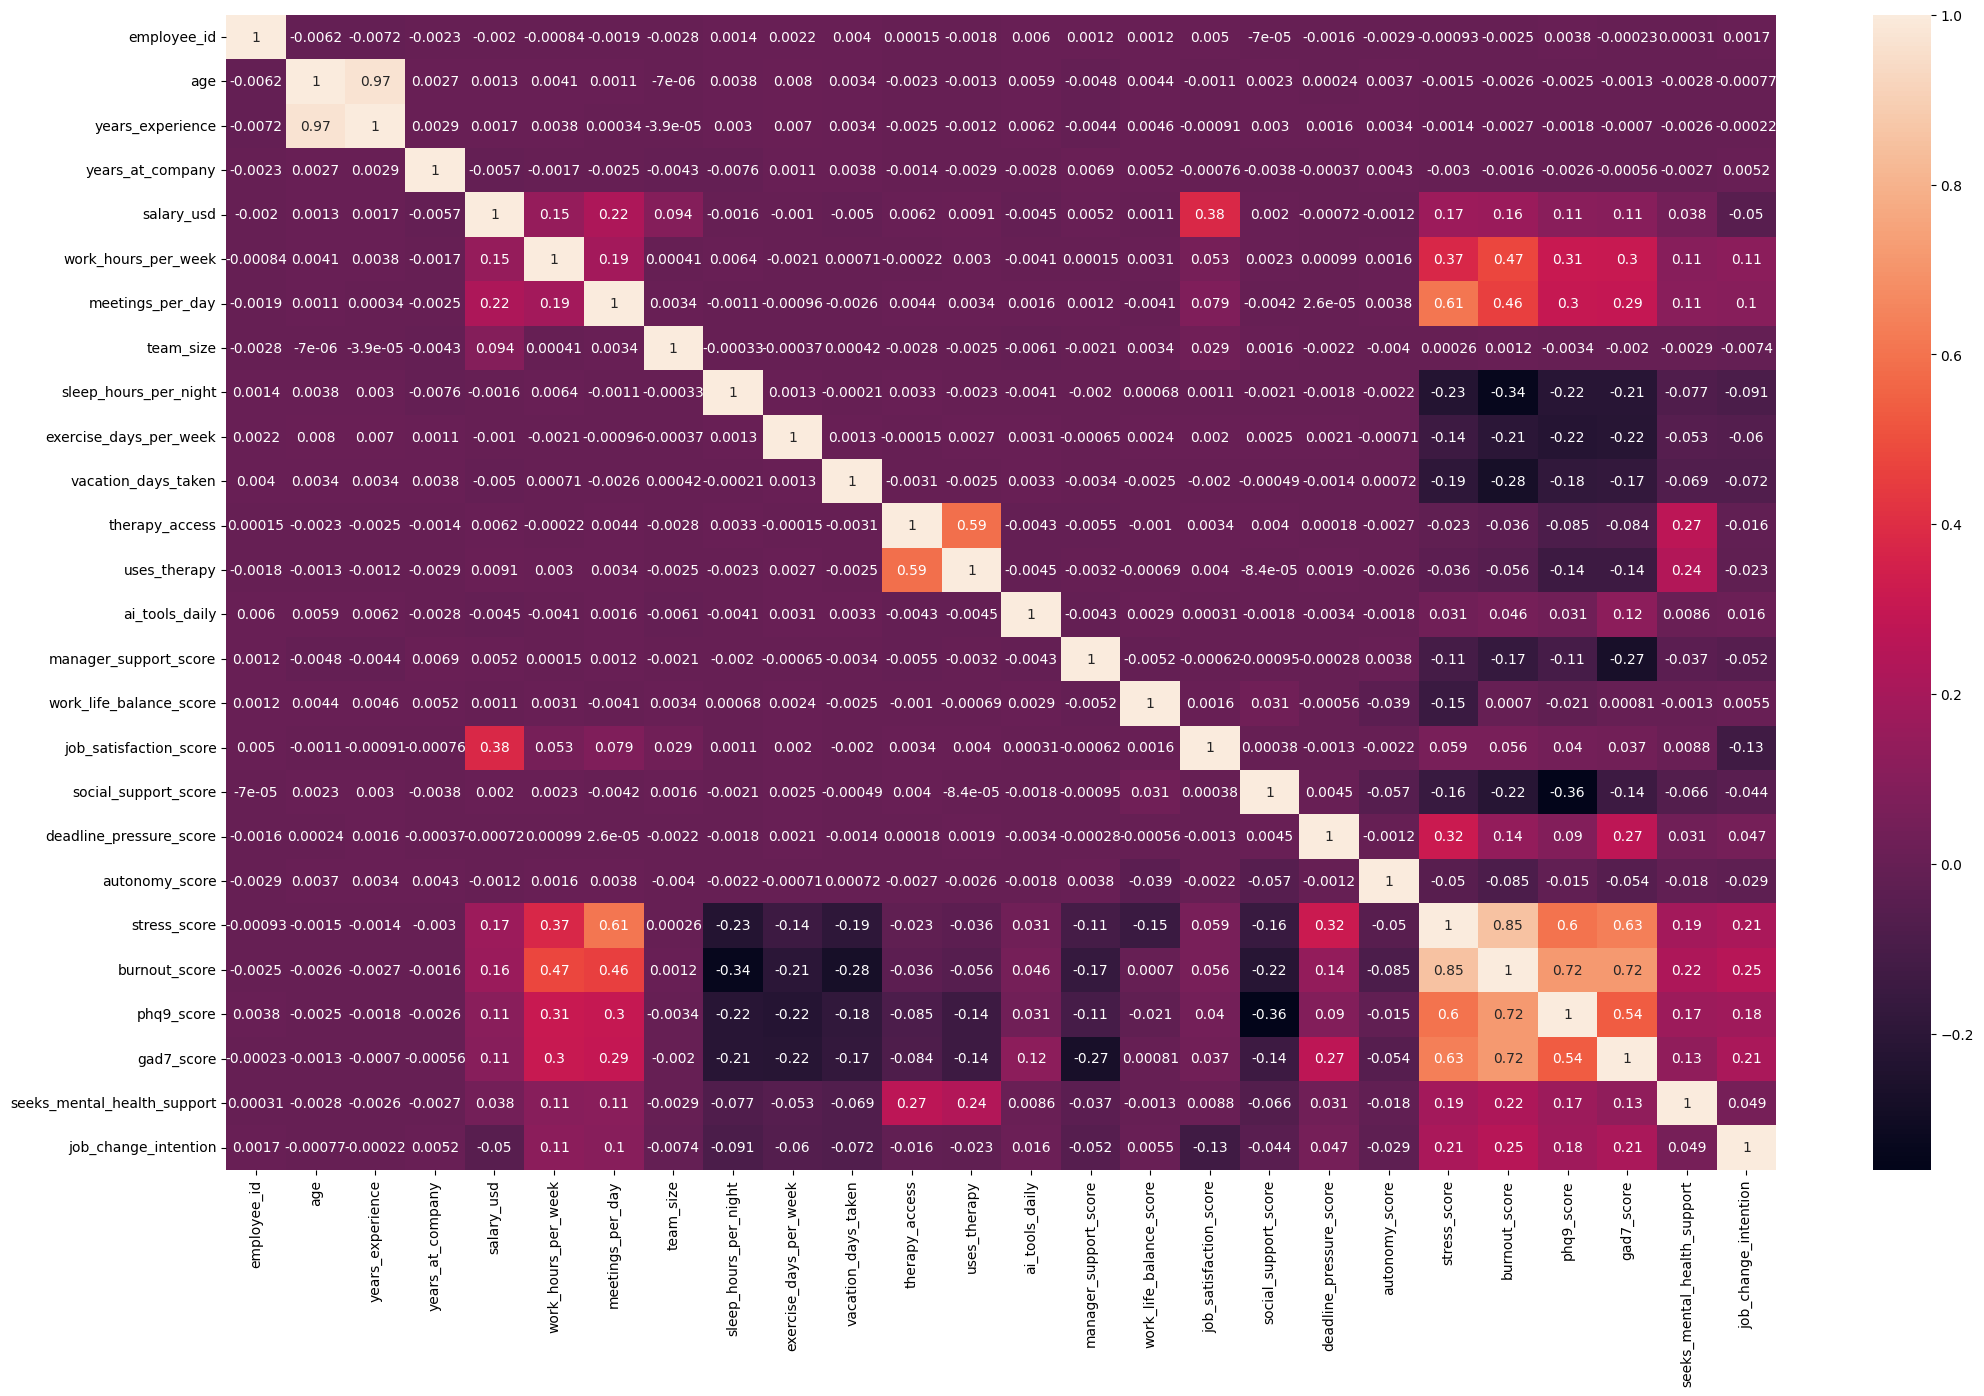

In [11]:
plt.figure(figsize=(25,15))
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [12]:
df['work_mode'].value_counts()

work_mode
Hybrid     39856
Remote     34936
On-site    25208
Name: count, dtype: int64

<Axes: xlabel='burnout_score', ylabel='burnout_level'>

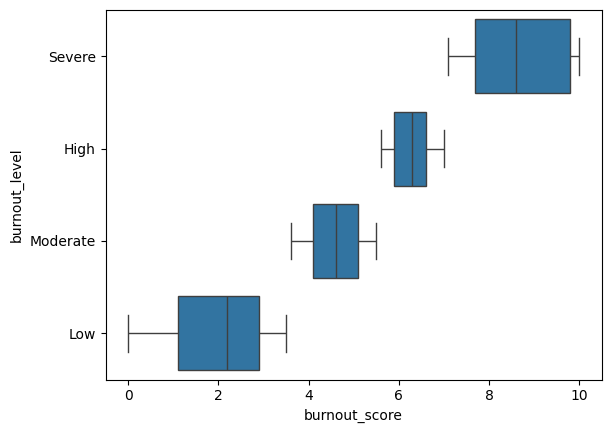

In [13]:
sns.boxplot(x = df['burnout_score'], y = df['burnout_level'])

<Axes: xlabel='burnout_score', ylabel='Count'>

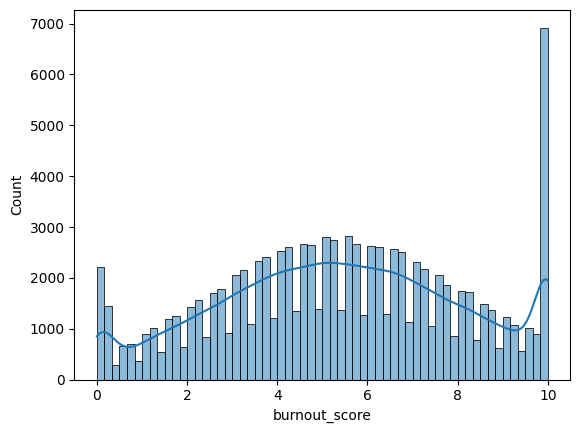

In [14]:
sns.histplot(data=df, x='burnout_score', kde=True)

<Axes: xlabel='burnout_level', ylabel='count'>

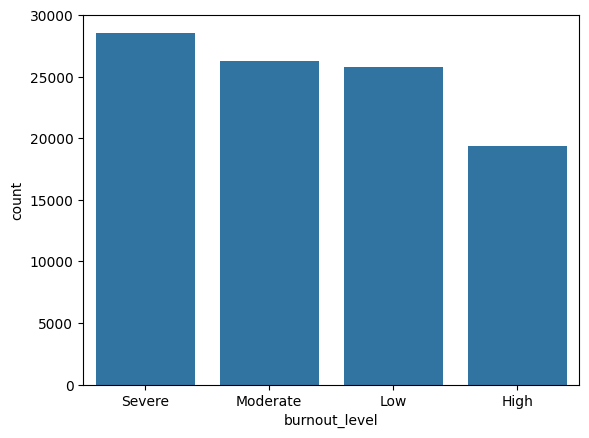

In [15]:
sns.countplot(data=df, x='burnout_level', order=df['burnout_level'].value_counts().index)

<Axes: xlabel='country', ylabel='count'>

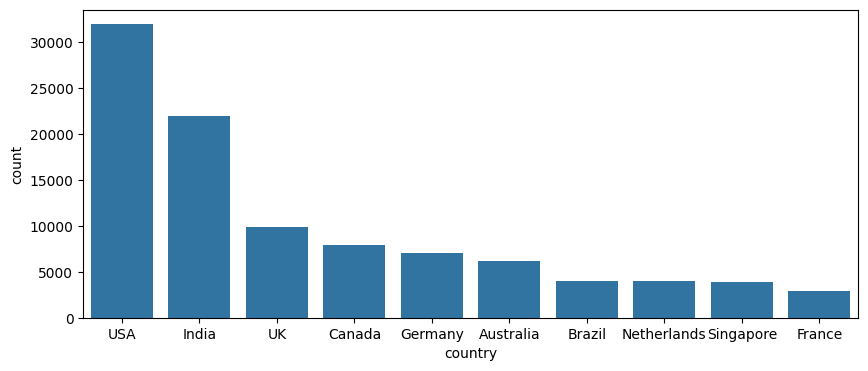

In [16]:
plt.figure(figsize=(10,4))
sns.countplot(x = df['country'], order=df['country'].value_counts().index)

In [17]:
df['gender'].value_counts()

gender
Male                 65243
Female               29759
Non-binary            3994
Prefer not to say     1004
Name: count, dtype: int64

In [18]:
df['job_role'].value_counts()

job_role
Software Engineer         20080
Data Scientist            12029
ML Engineer               10114
Data Analyst               8028
Backend Developer          7996
Frontend Developer         7970
Product Manager            7965
DevOps Engineer            7949
Full Stack Developer       6907
Cybersecurity Engineer     4011
Cloud Engineer             3917
QA Engineer                3034
Name: count, dtype: int64

In [19]:
df['seniority_level'].value_counts()

seniority_level
Mid          28092
Senior       24852
Junior       20230
Lead         11928
Manager       9915
Principal     4983
Name: count, dtype: int64

In [20]:
df['company_size'].value_counts()

company_size
Mid (201-1000)        25062
Large (1001-5000)     22027
Startup (1-50)        19771
Small (51-200)        18067
Enterprise (5000+)    15073
Name: count, dtype: int64

In [21]:
df['industry'].value_counts()

industry
SaaS / Cloud             19957
Fintech                  15064
E-commerce               12057
AI / ML Startup          11957
Healthcare Tech          10004
Cybersecurity             7900
Consulting                7012
Enterprise Software       6098
Gaming                    5936
Social Media / AdTech     4015
Name: count, dtype: int64

In [22]:
df['phq9_category'].value_counts()

phq9_category
None (0-4)                   40918
Mild (5-9)                   32611
Moderate (10-14)             20133
Moderately Severe (15-19)     5773
Severe (20-27)                 565
Name: count, dtype: int64

In [23]:
df['gad7_category'].value_counts()

gad7_category
Minimal (0-4)       47532
Mild (5-9)          36912
Moderate (10-14)    14191
Severe (15-21)       1365
Name: count, dtype: int64

### Checking Outliers

In [24]:
num_features = df.select_dtypes(include='number')

Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.4 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())

employee_id                        0
age                              167
years_experience                   0
years_at_company                4600
salary_usd                       430
work_hours_per_week              353
meetings_per_day                 653
team_size                       3437
sleep_hours_per_night            747
exercise_days_per_week             0
vacation_days_taken              275
therapy_access                     0
uses_therapy                   15185
ai_tools_daily                     0
manager_support_score              0
work_life_balance_score            0
job_satisfaction_score             0
social_support_score               0
deadline_pressure_score          702
autonomy_score                   485
stress_score                       0
burnout_score                      0
phq9_score                        64
gad7_score                       130
seeks_mental_health_support        0
job_change_intention               0
dtype: int64


# Data Cleaning  

### Drop Duplicates

In [25]:
df.drop(columns='employee_id', inplace=True)

In [26]:
df = df.drop(columns=['age', 'burnout_level', 'phq9_category', 'gad7_category',
                      'stress_score', 'phq9_score', 'gad7_score'])

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df.drop_duplicates()

,gender,country,job_role,seniority_level,years_experience,years_at_company,company_size,industry,work_mode,salary_usd,...,ai_tools_daily,manager_support_score,work_life_balance_score,job_satisfaction_score,social_support_score,deadline_pressure_score,autonomy_score,burnout_score,seeks_mental_health_support,job_change_intention
0,Male,India,Software Engineer,Lead,11,6.4,Small (51-200),Healthcare Tech,Remote,40000,...,0,6.0,4.4,2.8,3.9,8.3,6.1,10.0,1,1
1,Non-binary,USA,Full Stack Developer,Manager,0,5.7,Startup (1-50),Fintech,Hybrid,131165,...,1,7.6,4.0,3.7,3.8,9.3,5.4,7.0,1,1
2,Prefer not to say,USA,Software Engineer,Lead,14,5.6,Mid (201-1000),Fintech,On-site,169180,...,1,4.8,6.2,4.8,5.7,8.9,4.1,8.5,0,1
3,Non-binary,USA,Software Engineer,Lead,14,1.2,Mid (201-1000),SaaS / Cloud,Remote,147770,...,1,6.7,1.8,5.0,4.8,6.2,7.3,10.0,0,1
4,Non-binary,France,ML Engineer,Junior,0,3.0,Small (51-200),AI / ML Startup,Hybrid,57228,...,1,7.9,5.0,1.0,4.4,5.4,4.4,5.4,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Female,USA,Data Scientist,Senior,17,1.9,Startup (1-50),Gaming,Remote,111983,...,0,5.2,3.6,8.7,4.4,5.9,4.0,6.2,0,1
99996,Female,India,Product Manager,Manager,17,1.4,Small (51-200),SaaS / Cloud,Remote,55010,...,0,7.9,4.4,5.3,3.6,7.3,5.6,6.5,0,0
99997,Male,USA,Software Engineer,Mid,22,0.7,Large (1001-5000),Cybersecurity,Remote,110019,...,1,7.6,9.3,8.0,4.4,2.9,3.8,0.6,0,0
99998,Male,UK,Data Scientist,Senior,7,5.6,Small (51-200),E-commerce,On-site,81074,...,0,5.8,4.5,7.1,10.0,2.7,4.6,3.8,1,0


# Skewness

In [29]:
num_cols = df.select_dtypes(include='number')
num_cols.skew()
# near to 0 -> Centralized
# negative -> left skewed
# positive (greater than 0) -> right skewed
#To correct, we use log transformation

years_experience               0.371758
years_at_company               1.813321
salary_usd                     0.787233
work_hours_per_week            0.100107
meetings_per_day               0.380868
team_size                      1.117572
sleep_hours_per_night          0.016813
exercise_days_per_week         0.155678
vacation_days_taken            0.107633
therapy_access                 0.672616
uses_therapy                   1.940257
ai_tools_daily                -1.036489
manager_support_score         -0.051509
work_life_balance_score        0.007134
job_satisfaction_score         0.112155
social_support_score           0.017202
deadline_pressure_score       -0.185469
autonomy_score                -0.035372
burnout_score                 -0.059199
seeks_mental_health_support    0.008440
job_change_intention           0.771657
dtype: float64

# Encoding Strategy

Before we jump into code, let's decide how each categorical column should be encoded --this decision matters more than the code itself.
```
- `BMI Category` --> Ordinal Encoding. Its categories have a real, meaningful order: Normal <  Normal Weight < Overweight < Obese. We already saw in EDA that the score drops step by step as BMI increase -- encoding it as 0, 1, 2, 3 preserves that order for the model.
- Gender, Occupation, Grouped Blood Pressure --> One-Hot Encoding. These categories have no natural order - "Nurse" isn't greater than "Doctor".One-hot encoding creates a separate 0/1 column per category so the model doesn't accidentally assume a false ranking.
```
We'll implement both of these inside a single columnTransformer in the next step, rather than doing it manually column by column -- that keeps preprocessing consistent adn reusable.

# Train-Test Split

In [30]:
from sklearn.model_selection import train_test_split

skewed_cols = ['years_at_company', 'team_size', 'uses_therapy', 'ai_tools_daily',
               'manager_support_score', 'deadline_pressure_score', 'autonomy_score',
               'job_change_intention', 'salary_usd', 'therapy_access']
other_numeric_cols = [ 'years_experience', 'work_hours_per_week', 'meetings_per_day',
                      'sleep_hours_per_night', 'exercise_days_per_week', 'vacation_days_taken',
                      'work_life_balance_score', 'job_satisfaction_score', 'social_support_score',
                      'seeks_mental_health_support']
ordinal_cols     = ['company_size', 'seniority_level']
normal_cols      = ['gender', 'country', 'job_role', 'industry', 'work_mode']

feature_col = skewed_cols + other_numeric_cols + ordinal_cols + normal_cols

# Drop the row that has completely missing values (e.g. index 5530)
df_cleaned = df.dropna(how='all')
# Alternatively, drop any row where the target 'burnout_score' is missing
df_cleaned = df_cleaned.dropna(subset=['burnout_score'])

# Define our features and target using the cleaned data
X = df_cleaned[feature_col]
y = df_cleaned['burnout_score']

# Re-split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"New dataset shape: {df_cleaned.shape}")

New dataset shape: (100000, 28)


In [31]:
df.columns.tolist()

['gender',
 'country',
 'job_role',
 'seniority_level',
 'years_experience',
 'years_at_company',
 'company_size',
 'industry',
 'work_mode',
 'salary_usd',
 'work_hours_per_week',
 'meetings_per_day',
 'team_size',
 'sleep_hours_per_night',
 'exercise_days_per_week',
 'vacation_days_taken',
 'therapy_access',
 'uses_therapy',
 'ai_tools_daily',
 'manager_support_score',
 'work_life_balance_score',
 'job_satisfaction_score',
 'social_support_score',
 'deadline_pressure_score',
 'autonomy_score',
 'burnout_score',
 'seeks_mental_health_support',
 'job_change_intention']

In [63]:
column = df['seeks_mental_health_support']

print(column.value_counts())
print(f"Min: {column.min()}")
print(f"Max: {column.max()}")

seeks_mental_health_support
0    50211
1    49789
Name: count, dtype: int64
Min: 0
Max: 1


# Preprocessng using ColumnTransformer

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
#1. Skewed Pipeline
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())
])

#2. Numeric features
plain_numeric_pipeline = Pipeline(steps=[
    ('scale', StandardScaler())
])

# 3. Ordinal features
categories = [
    ['Startup (1-50)', 'Small (51-200)', 'Mid (201-1000)', 'Large (1001-5000)', 'Enterprise (5000+)'],
    ['Junior', 'Mid', 'Senior', 'Lead', 'Manager', 'Principal'],
]
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=categories))
])

# 4. Normal Features
normal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])


# (konsi_pipeline, konsa_feature)
preprocessor = ColumnTransformer(transformers= [
    ("Skew_Pipeline", skew_pipeline, skewed_cols),
    ("Plain_Pipeline", plain_numeric_pipeline, other_numeric_cols),
    ("Ordinal_Pipeline", ordinal_pipeline, ordinal_cols),
    ("Normal_Pipeline", normal_pipeline, normal_cols)
])


# Build a Pipeline

Why Pipeline matters: a Piepline chains preprocessing adn the model into a single objecct. Calling .fit() once does both steps in the correct order, and calling .predict() on brand-new raw data automatically applies the exact same preprocessing that was used during training -- no risk of forgetting a step or applying it inconsistently.

Why companies prefer this: when this model gets deployed(which we're doing in Part 2 with FastAPI), the API doesn't need to know anything about scaling, encoding, or log transforms -- it just loads one saved pipeline object and calls .predict() on raw input. That's a huge reduction in what can go wrong in production.

3We'll build two pieplines below -- one per model -- so we can fairly compare them.

# Model Building

We're comparing two models here because the comparison itself teaches something useful -- a plain Linear Regression baseline vedrsus a Random Forest, which can capture the non-linear patterns we spotted back in EDA.

### - Baseline: Linear Regression

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
lr_preds = lr_pipeline.predict(X_test)
lr_preds_train = lr_pipeline.predict(X_train)

lr_r2_testing = r2_score(y_test, lr_preds)
lr_r2_training = r2_score(y_train, lr_preds_train)
lr_mae = mean_absolute_error(y_test, lr_preds)

print(f"Accuracy of Training: {lr_r2_testing}")
print(f"Accuracy of Testing: {lr_r2_training}")
print(f"Mean Absolute Error; {lr_mae}")

Accuracy of Training: 0.7204863888601987
Accuracy of Testing: 0.7233880971031619
Mean Absolute Error; 1.1297743473998092


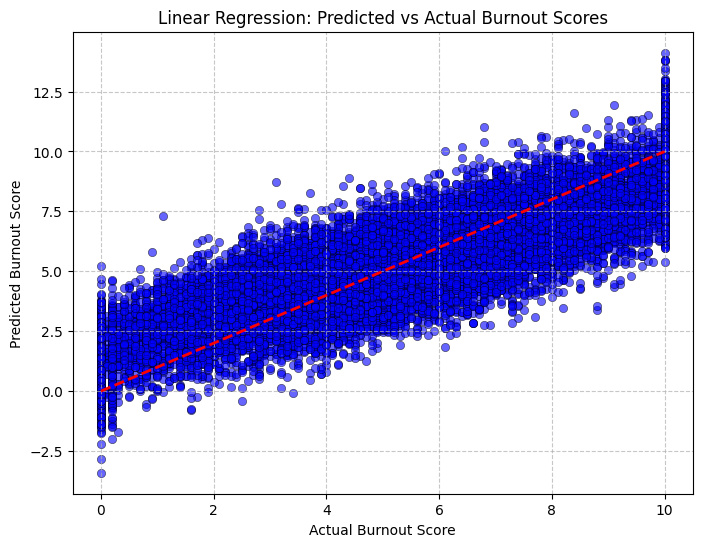

In [35]:
# Visualize predictions vs Actual values for the best model
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=lr_preds, alpha=0.6, color='blue', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Linear Regression: Predicted vs Actual Burnout Scores')
plt.xlabel('Actual Burnout Score')
plt.ylabel('Predicted Burnout Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [38]:
# Save the pipeline using joblib but with the .pkl extension
import joblib
model_pkl_filename = 'lr_model.pkl'
joblib.dump(lr_pipeline, model_pkl_filename)
print(f"Model pipeline successfully saved as '{model_pkl_filename}'!")

Model pipeline successfully saved as 'lr_model.pkl'!


### - Random Forest (default settings)

Same preprocessor, different model at the end -- that's the entire point of building the pipeline once.

In [36]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

# Define the pipeline explicitly in this cell to prevent NameError
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("random forest", RandomForestRegressor(random_state=42))
])

# Fit the Random Forest pipeline
rf_pipeline.fit(X_train, y_train)

# Make predictions
rf_preds = rf_pipeline.predict(X_test)
rf_preds_train = rf_pipeline.predict(X_train)

# Evaluate metrics
rf_r2_testing = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_train)
rf_mae = mean_absolute_error(y_test, rf_preds)

print(f"Random Forest Training (R2): {rf_r2_training:.4f}")
print(f"Random Forest Testing (R2): {rf_r2_testing:.4f}")
print(f"Random Forest Mean Absolute Error: {rf_mae:.4f}")

Random Forest Training (R2): 0.9550
Random Forest Testing (R2): 0.6769
Random Forest Mean Absolute Error: 1.2240


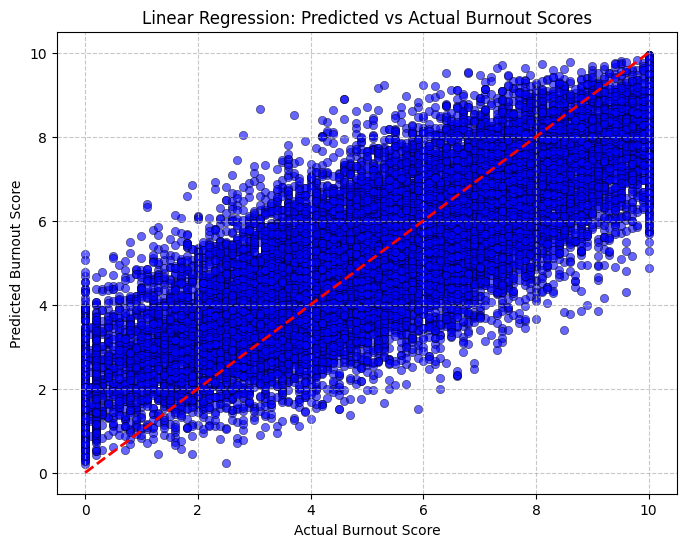

In [39]:
# Visualize predictions vs Actual values for the best model
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=rf_preds, alpha=0.6, color='blue', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Linear Regression: Predicted vs Actual Burnout Scores')
plt.xlabel('Actual Burnout Score')
plt.ylabel('Predicted Burnout Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### - Random Forest (settings)

In [52]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=10,   # biggest lever against overfitting
    max_features=0.5,
    n_jobs=-1,
    random_state=42,
)

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("random forest", rf)
])

rf_pipeline.fit(X_train, y_train)

rf_preds = rf_pipeline.predict(X_test)
rf_preds_train = rf_pipeline.predict(X_train)

# Evaluate metrics
rf_r2_testing = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_train)
rf_mae = mean_absolute_error(y_test, rf_preds)

print(f"Random Forest Training (R2): {rf_r2_training:.4f}")
print(f"Random Forest Testing (R2): {rf_r2_testing:.4f}")
print(f"Random Forest Mean Absolute Error: {rf_mae:.4f}")

Random Forest Training (R2): 0.7558
Random Forest Testing (R2): 0.6342
Random Forest Mean Absolute Error: 1.3065


In [53]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

for name, model in [("Linear", LinearRegression()),
                    ("Ridge", Ridge(alpha=1.0)),
                    ("RF tuned", rf)]:
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")
    print(f"{name}: {scores.mean():.3f} (+/- {scores.std():.3f})")

Linear: 0.721 (+/- 0.018)
Ridge: 0.721 (+/- 0.018)
RF tuned: 0.606 (+/- 0.008)


In [54]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

# Define rf_pipeline explicitly to avoid NameError if earlier cell wasn't run
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("random forest", RandomForestRegressor(random_state=42))
])

# Fit the Random Forest pipeline
rf_pipeline.fit(X_train, y_train)

# Make predictions
rf_preds = rf_pipeline.predict(X_test)
rf_preds_train = rf_pipeline.predict(X_train)

# Evaluate metrics
rf_r2_testing = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_train)
rf_mae = mean_absolute_error(y_test, rf_preds)

print(f"Random Forest Training (R2): {rf_r2_training:.4f}")
print(f"Random Forest Testing (R2): {rf_r2_testing:.4f}")
print(f"Random Forest Mean Absolute Error: {rf_mae:.4f}")

Random Forest Training (R2): 0.9476
Random Forest Testing (R2): 0.6505
Random Forest Mean Absolute Error: 1.2727


In [55]:
from sklearn.model_selection import RandomizedSearchCV

# 'rf__' with whatever string name you gave to your RandomForest step in your
# pipeline definition
param_grid = {
    'random forest__n_estimators' : [100, 200, 300],
    'random forest__max_depth' : [5, 10, 15],
    'random forest__min_samples_split' : [2, 5, 10],
    'random forest__min_samples_leaf' : [1, 2, 4]
}

random_search =  RandomizedSearchCV(
    estimator = rf_pipeline,
    param_distributions= param_grid,
    n_iter = 15,
    cv= 5,
    scoring= 'r2',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('Skew_Pipeline',
                                                                               Pipeline(steps=[('log_transform',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['years_at_company',
                                                                                'team_size',
                                                                                'uses_therapy',
                                                                                'ai_tools_daily',
                                                                                'manager_support_score',
                                                                                'deadline_pressure_score',
                                                                                'autonomy_score',...
                                                                               ['gender',
                                                                                'country',
                                                                                'job_role',
                                                                                'industry',
                                                                                'work_mode'])])),
                                             ('random forest',
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'random forest__max_depth': [5, 10, 15],
                                        'random forest__min_samples_leaf': [1,
                                                                            2,
                                                                            4],
                                        'random forest__min_samples_split': [2,
                                                                             5,
                                                                             10],
                                        'random forest__n_estimators': [100,
                                                                        200,
                                                                        300]},
                   random_state=42, scoring='r2')

In [56]:
random_search.best_params_

{'random forest__n_estimators': 300,
 'random forest__min_samples_split': 5,
 'random forest__min_samples_leaf': 2,
 'random forest__max_depth': 15}

In [57]:
rf_best_pipeline = random_search.best_params_
rf_best_preds = random_search.predict(X_test)

print(f"R2 Score for random forest after hyperparameter tuning {r2_score(y_test, rf_best_preds)}")
print(f"MAE Score for random forest after hyperparameter tuning {mean_absolute_error(y_test, rf_best_preds)}")


R2 Score for random forest after hyperparameter tuning 0.6537981890413531
MAE Score for random forest after hyperparameter tuning 1.2651812095938664


In [58]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Retrieve the best estimator pipeline from our randomized search
best_rf_pipeline = random_search.best_estimator_

# 2. Generate predictions on both training and testing sets
tuned_rf_train_preds = best_rf_pipeline.predict(X_train)
tuned_rf_test_preds = best_rf_pipeline.predict(X_test)

# 3. Calculate evaluation metrics
tuned_rf_r2_train = r2_score(y_train, tuned_rf_train_preds)
tuned_rf_r2_test = r2_score(y_test, tuned_rf_test_preds)
tuned_rf_mae = mean_absolute_error(y_test, tuned_rf_test_preds)
tuned_rf_rmse = np.sqrt(mean_squared_error(y_test, tuned_rf_test_preds))

print("--- Tuned Random Forest Regressor Performance ---")
print(f"Training R2 Score : {tuned_rf_r2_train:.5f}")
print(f"Testing R2 Score  : {tuned_rf_r2_test:.5f}")
print(f"MAE               : {tuned_rf_mae:.5f}")
print(f"RMSE              : {tuned_rf_rmse:.5f}")

--- Tuned Random Forest Regressor Performance ---
Training R2 Score : 0.92726
Testing R2 Score  : 0.65380
MAE               : 1.26518
RMSE              : 1.56659


In [59]:
# Compare all models in a structured DataFrame
metrics_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (Default)', 'Random Forest (Tuned)'],
    'Train R2': [lr_r2_training, rf_r2_training, tuned_rf_r2_train],
    'Test R2': [lr_r2_testing, rf_r2_testing, tuned_rf_r2_test],
    'MAE': [lr_mae, rf_mae, tuned_rf_mae]
})

display(metrics_comparison)

,Model,Train R2,Test R2,MAE
0,Linear Regression,0.729355,0.720991,1.129241
1,Random Forest (Default),0.947613,0.650486,1.272728
2,Random Forest (Tuned),0.927262,0.653798,1.265181


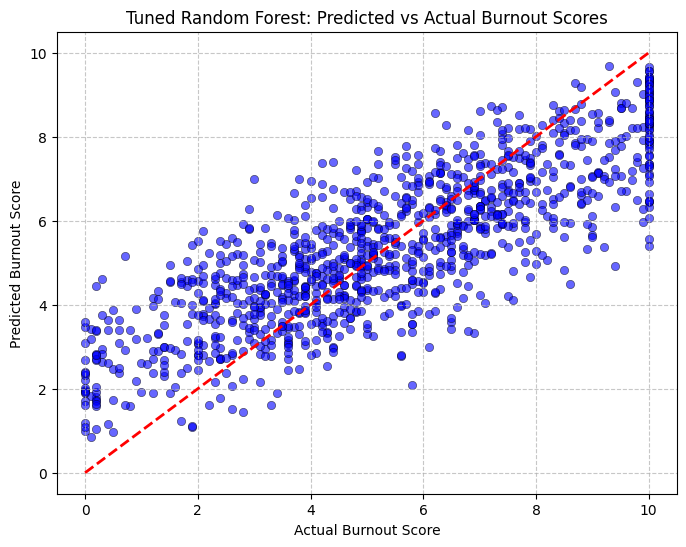

In [60]:
# Visualize predictions vs Actual values for the best model
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=tuned_rf_test_preds, alpha=0.6, color='blue', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Tuned Random Forest: Predicted vs Actual Burnout Scores')
plt.xlabel('Actual Burnout Score')
plt.ylabel('Predicted Burnout Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Key Components of the Plot

- Red Dashed Line: Represents perfect prediction where the predicted value exactly equals the actual value(y = x).
- Blue Dots: Represent individual data points from the test dataset.
- X-Axis: Shows the true, real-world observed stress levels

In [61]:
import joblib

# Save the best pipeline to a file
model_filename = 'best_rf_pipeline.joblib'
joblib.dump(best_rf_pipeline, model_filename)
print(f"Model pipeline successfully saved to '{model_filename}'!")

Model pipeline successfully saved to 'best_rf_pipeline.joblib'!


In [62]:
# Verify we can load the model back and make predictions
loaded_pipeline = joblib.load('best_rf_pipeline.joblib')

# Test with a single row from X_test
sample_test = X_test.iloc[[0]]
prediction = loaded_pipeline.predict(sample_test)

print("--- Test Loaded Model Pipeline ---")
print(f"Input Features:\n{sample_test.to_string(index=False)}\n")
print(f"Predicted Burnout Score : {prediction[0]:.2f}")
print(f"Actual Burnout Score    : {y_test.iloc[0]}")

--- Test Loaded Model Pipeline ---
Input Features:
 years_at_company  team_size  uses_therapy  ai_tools_daily  manager_support_score  deadline_pressure_score  autonomy_score  job_change_intention  salary_usd  therapy_access  years_experience  work_hours_per_week  meetings_per_day  sleep_hours_per_night  exercise_days_per_week  vacation_days_taken  work_life_balance_score  job_satisfaction_score  social_support_score  seeks_mental_health_support      company_size seniority_level gender country        job_role        industry work_mode
              8.4       29.0           0.0             1.0                   10.0                      6.4             6.1                   0.0     95173.0             0.0               0.0                 43.0               2.8                    4.8                     1.0                 17.0                      4.3                     5.0                   7.0                          1.0 Large (1001-5000)             Mid Female  Canada DevOps Engine

In [63]:
# Save the pipeline using joblib but with the .pkl extension
model_pkl_filename = 'best_rf_pipeline.pkl'
joblib.dump(best_rf_pipeline, model_pkl_filename)
print(f"Model pipeline successfully saved as '{model_pkl_filename}'!")

Model pipeline successfully saved as 'best_rf_pipeline.pkl'!
